# 06 · Comparatif des formats

Le pari du cours (slide 3), refait sur les taxis : les mêmes 100 000 courses enregistrées dans sept formats.
On mesure la taille, le temps d'écriture et de lecture, puis les types que chaque format conserve.

## 1. L'échantillon

On garde les 100 000 premières courses de mars. Tous les fichiers iront dans `output/comparatif/`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data")
OUTPUT = Path("../output")
DOSSIER = OUTPUT / "comparatif"
DOSSIER.mkdir(parents=True, exist_ok=True)

echantillon = pd.read_parquet(DATA / "yellow_tripdata_2026-03.parquet").head(100_000)
echantillon.shape

(100000, 20)

100 000 lignes et 20 colonnes : ce sont exactement ces données que l'on va écrire sept fois.

## 2. Deux petits outils

`taille_mo` donne la taille d'un fichier en Mo. `mesurer` chronomètre une fonction avec `time.perf_counter()` :
par exemple, `mesurer(echantillon.to_csv, chemin, index=False)` lance `echantillon.to_csv(chemin, index=False)` et renvoie sa durée en secondes.

In [2]:
def taille_mo(chemin):
    """Taille d'un fichier en Mo."""
    return round(chemin.stat().st_size / 1_000_000, 1)


def mesurer(fonction, chemin, **options):
    """Lance fonction(chemin, **options) et renvoie sa durée en secondes."""
    debut = time.perf_counter()
    fonction(chemin, **options)
    return round(time.perf_counter() - debut, 3)

## 3. Écrire les sept fichiers

Un dictionnaire associe chaque format à son fichier ; pour le `.csv.gz`, pandas compresse tout seul d'après l'extension.
On écrit ensuite les sept fichiers en chronométrant : comptez au moins 30 secondes, c'est Excel qui prend presque tout le temps.

In [3]:
fichiers = {
    "csv": DOSSIER / "courses.csv",
    "csv.gz": DOSSIER / "courses.csv.gz",
    "xlsx": DOSSIER / "courses.xlsx",
    "json": DOSSIER / "courses.json",
    "jsonl": DOSSIER / "courses.jsonl",
    "parquet snappy": DOSSIER / "courses_snappy.parquet",
    "parquet zstd": DOSSIER / "courses_zstd.parquet",
}

In [4]:
ecriture = {
    "csv": mesurer(echantillon.to_csv, fichiers["csv"], index=False),
    "csv.gz": mesurer(echantillon.to_csv, fichiers["csv.gz"], index=False),
    "xlsx": mesurer(echantillon.to_excel, fichiers["xlsx"], index=False),
    "json": mesurer(echantillon.to_json, fichiers["json"], orient="records", date_format="iso"),
    "jsonl": mesurer(echantillon.to_json, fichiers["jsonl"], orient="records", lines=True, date_format="iso"),
    "parquet snappy": mesurer(echantillon.to_parquet, fichiers["parquet snappy"], compression="snappy"),
    "parquet zstd": mesurer(echantillon.to_parquet, fichiers["parquet zstd"], compression="zstd"),
}
pd.Series(ecriture, name="ecriture_s")

csv                1.063
csv.gz             2.892
xlsx              31.106
json               0.423
jsonl              0.669
parquet snappy     0.058
parquet zstd       0.068
Name: ecriture_s, dtype: float64

Excel est de très loin le plus lent à écrire : une demi-minute ou plus.
Parquet s'écrit en une fraction de seconde, plus vite même que le CSV.

## 4. Relire et comparer

On relit chaque fichier en entier avec le même chronomètre (encore au moins 15 secondes, à cause d'Excel), puis on range tout dans un tableau trié par taille.

In [5]:
lecture = {
    "csv": mesurer(pd.read_csv, fichiers["csv"]),
    "csv.gz": mesurer(pd.read_csv, fichiers["csv.gz"]),
    "xlsx": mesurer(pd.read_excel, fichiers["xlsx"]),
    "json": mesurer(pd.read_json, fichiers["json"]),
    "jsonl": mesurer(pd.read_json, fichiers["jsonl"], lines=True),
    "parquet snappy": mesurer(pd.read_parquet, fichiers["parquet snappy"]),
    "parquet zstd": mesurer(pd.read_parquet, fichiers["parquet zstd"]),
}

In [6]:
tailles = {}
for nom, chemin in fichiers.items():
    tailles[nom] = taille_mo(chemin)

comparatif = pd.DataFrame({"taille_mo": tailles, "ecriture_s": ecriture, "lecture_s": lecture})
comparatif = comparatif.sort_values("taille_mo")
comparatif

,taille_mo,ecriture_s,lecture_s
csv.gz,1.9,2.892,0.257
parquet zstd,1.9,0.068,0.009
parquet snappy,2.2,0.058,0.012
xlsx,8.7,31.106,15.544
csv,11.1,1.063,0.235
json,45.5,0.423,0.867
jsonl,45.5,0.669,0.963


Parquet et le CSV compressé pèsent environ 2 Mo ; le JSON (45,5 Mo) pèse 4 fois le CSV (11,1 Mo), car il répète les noms de colonnes à chaque course.
Parquet se lit plus de 10 fois plus vite que le CSV ; Excel, pourtant plus léger que le CSV (c'est un zip), est des dizaines de fois plus lent à lire.

## 5. En image

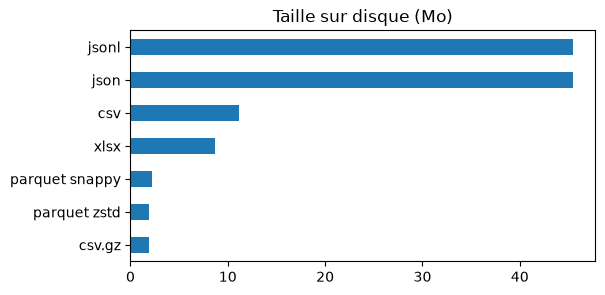

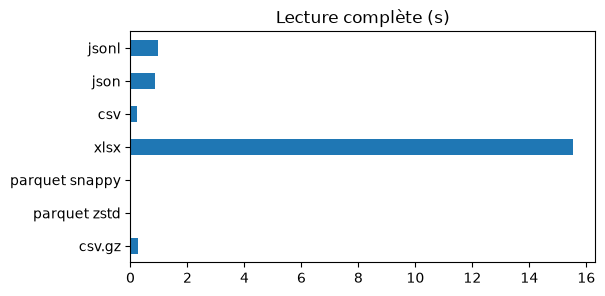

In [7]:
comparatif["taille_mo"].plot.barh(title="Taille sur disque (Mo)", figsize=(6, 3))
plt.show()
comparatif["lecture_s"].plot.barh(title="Lecture complète (s)", figsize=(6, 3))
plt.show()

Les deux JSON sont les plus lourds ; Excel est si lent à lire qu'à côté de lui les autres barres paraissent minuscules.
Parquet a les barres les plus courtes sur les deux graphiques (à égalité avec le `csv.gz` pour la taille).

## 6. Le vrai fichier : le mois complet

Le bandeau de la slide 17 : les 3,95 millions de courses en CSV contre Parquet.
Le CSV vient du notebook 02 ; s'il n'existe pas, la cellule le crée (au moins 30 secondes).

In [8]:
chemin_parquet = DATA / "yellow_tripdata_2026-03.parquet"
chemin_csv = OUTPUT / "courses_2026-03.csv"
if not chemin_csv.exists():
    pd.read_parquet(chemin_parquet).to_csv(chemin_csv, index=False)

taille_mo(chemin_csv), taille_mo(chemin_parquet)

(424.7, 67.9)

424,7 Mo en CSV contre 67,9 Mo en Parquet : pour les mêmes courses, le CSV est 6 fois plus lourd.

On chronomètre la lecture complète des deux fichiers, puis celle de 2 colonnes seulement en Parquet.
`low_memory=False` évite un avertissement de pandas sur la colonne `store_and_fwd_flag`, aux types mélangés.

In [9]:
deux_colonnes = ["trip_distance", "total_amount"]
pd.Series({
    "csv": mesurer(pd.read_csv, chemin_csv, low_memory=False),
    "parquet": mesurer(pd.read_parquet, chemin_parquet),
    "parquet, 2 colonnes": mesurer(pd.read_parquet, chemin_parquet, columns=deux_colonnes),
}, name="lecture_s")

csv                    11.012
parquet                 0.213
parquet, 2 colonnes     0.027
Name: lecture_s, dtype: float64

Le CSV demande au moins une dizaine de secondes ; Parquet, des dizaines de fois plus rapide, quelques dixièmes seulement.
Avec 2 colonnes, Parquet ne lit que ce qu'on lui demande : quelques centièmes de seconde.

## 7. Ce qui se perd en route

On relit l'échantillon depuis quatre fichiers et on compare le type de trois colonnes.
Pour Excel, on prend le moteur rapide `calamine` vu au notebook 03.

In [10]:
colonnes = ["tpep_pickup_datetime", "VendorID", "passenger_count"]
types_relus = pd.DataFrame({
    "origine": echantillon[colonnes].dtypes,
    "csv": pd.read_csv(fichiers["csv"])[colonnes].dtypes,
    "jsonl": pd.read_json(fichiers["jsonl"], lines=True)[colonnes].dtypes,
    "xlsx": pd.read_excel(fichiers["xlsx"], engine="calamine")[colonnes].dtypes,
    "parquet": pd.read_parquet(fichiers["parquet zstd"])[colonnes].dtypes,
})
types_relus

,origine,csv,jsonl,xlsx,parquet
tpep_pickup_datetime,datetime64[us],str,str,datetime64[us],datetime64[us]
VendorID,int32,int64,int64,int64,int32
passenger_count,float64,float64,int64,int64,float64


Seul Parquet rend exactement les types d'origine. Le CSV et le JSON Lines relisent la date comme du texte (`str`) ;
Excel garde la date mais, comme eux, change `VendorID` de `int32` en `int64`.

## 8. Le geste propre : CSV vers Parquet avec un schéma

Pour passer d'un CSV à Parquet sans rien perdre, on **déclare** les types au lieu de les laisser deviner (code de la slide 19, avec pyarrow).

In [11]:
import pyarrow as pa
import pyarrow.csv as pv
import pyarrow.parquet as pq

types = {
    "tpep_pickup_datetime": pa.timestamp("us"),
    "tpep_dropoff_datetime": pa.timestamp("us"),
    "VendorID": pa.int32(),
    "PULocationID": pa.int32(),
    "DOLocationID": pa.int32(),
}

In [12]:
opts = pv.ConvertOptions(column_types=types)
table = pv.read_csv(fichiers["csv"], convert_options=opts)
pq.write_table(table, DOSSIER / "courses_propre.parquet", compression="zstd")

propre = pd.read_parquet(DOSSIER / "courses_propre.parquet")
print("Mêmes types que l'échantillon d'origine :", propre.dtypes.equals(echantillon.dtypes))

Mêmes types que l'échantillon d'origine : True


Les 20 colonnes ont retrouvé leurs types d'origine : les dates en dates, les identifiants en int32.
Un type se déclare, il ne se devine pas.

## Exercices

### ✍️ Exercice 1 — Lire 2 colonnes d'un CSV

Peut-on lire vite seulement 2 colonnes du CSV du mois ? Chronométrez `pd.read_csv` avec `usecols=deux_colonnes` et comparez avec Parquet (section 6).

In [13]:
# ✅ Solution
mesurer(pd.read_csv, chemin_csv, usecols=deux_colonnes)

2.683

Quelques secondes : mieux que la lecture complète, mais des dizaines de fois plus lent que Parquet sur les mêmes 2 colonnes.
Le CSV doit quand même parcourir tout le fichier ; Parquet saute directement aux colonnes demandées.

### ✍️ Exercice 2 — Quel format pour quel usage ? (slide 23)

Pour chaque scénario de la boutique, choisissez un format et justifiez en une phrase.

1. Le service financier veut chaque lundi les paiements de la semaine, une feuille par ville.
2. L'application mobile envoie un événement à chaque clic : vue produit, ajout au panier.
3. Analyser trois ans de commandes, environ 50 millions de lignes, dans un notebook.
4. Un transporteur envoie chaque nuit les statuts de livraison depuis un vieux logiciel.
5. Exposer le catalogue produits et ses variantes (tailles, couleurs) à une application partenaire.
6. Un client exerce son droit à l'effacement : supprimer ses commandes de l'historique, et prouver qui a supprimé quoi.

**✅ Solution**

| Scénario | Format | Pourquoi |
|---|---|---|
| 1. Rapport du lundi | Excel | Un rapport pour des humains, avec une feuille par ville dans un seul fichier. |
| 2. Clics de l'application | JSON Lines | Chaque événement est une ligne ajoutée à la fin du fichier, sans réécrire le reste. |
| 3. 50 millions de lignes | Parquet | Compact, typé, et on ne lit que les colonnes utiles. |
| 4. Vieux logiciel du transporteur | CSV | Tout logiciel sait en produire (en précisant séparateur et encodage). |
| 5. Catalogue et variantes | JSON | Le format des API, qui accepte les listes imbriquées (les variantes). |
| 6. Droit à l'effacement | Delta Lake ou Iceberg | Un `DELETE` dans une transaction, et l'historique garde qui a supprimé quoi. |

## À retenir

La carte complète (slide 24) :

| Critère | CSV, TSV | Excel | JSON | JSON Lines | Parquet | Delta, Iceberg |
|---|---|---|---|---|---|---|
| Lisible | oui | dans Excel | oui | oui | non | non |
| Typé | non | par cellule | en partie | en partie | oui | oui, évolutif |
| Imbrication | non | non | oui | oui | oui | oui |
| Taille | médiocre | moyenne | mauvaise | mauvaise | excellente | excellente |
| Vitesse de lecture | moyenne | très lente | lente | lente | excellente | excellente |
| Lecture partielle | non | non | non | non | oui | oui |
| Ajout ligne à ligne | oui | non | non | oui | non | par transactions |
| Mise à jour | réécrire | à la main | réécrire | réécrire | réécrire | UPDATE, DELETE |
| Interopérabilité | universelle | métier | web, API | logs, BigQuery | outils data | moteurs lakehouse |
| Usage type | échange simple | rapports métier | API, config | logs, flux | analyse | tables vivantes |

- Mesuré ici : Parquet est aussi léger que le CSV compressé et de loin le plus rapide à lire ; JSON est le plus lourd, Excel le plus lent.
- CSV et Excel pour les humains, JSON pour échanger, Parquet pour analyser, Delta ou Iceberg pour les tables vivantes.
- Toujours expliciter le séparateur, l'encodage, les types et le fuseau horaire.
- Le schéma se décide à l'entrée et voyage avec la donnée.